## Here i'm learning PyTorch:

### Resource used:
- https://www.youtube.com/playlist?list=PLZ2ps__7DhBZ2SJesWPtsowraJcSdanc3
- [PyTorch internals](https://blog.ezyang.com/2019/05/pytorch-internals/)

## Tensor: What is it?

In PyTorch (and machine learning in general), a **tensor** is a generalization of vectors and matrices to an arbitrary number of dimensions. It's essentially a multi-dimensional array.

Here's a more common way to think about tensor dimensions:

- **0-D Tensor (Scalar):** A single number. E.g., `5`
- **1-D Tensor (Vector):** An array of numbers. E.g., `[1, 2, 3]`
- **2-D Tensor (Matrix):** A grid of numbers. E.g., `[[1, 2], [3, 4]]` (often used for grayscale images or a batch of vectors)
- **3-D Tensor:** A collection of matrices. E.g., `[ [ [1], [2] ], [ [3], [4] ] ]` (often used for color images, where each matrix is a color channel, or a batch of 2D data)
- **4-D Tensor:** A collection of 3D tensors. E.g., a batch of color images `(batch_size, channels, height, width)` or a video `(frames, channels, height, width)`
- **5-D Tensor:** A collection of 4D tensors. E.g., a batch of videos `(batch_size, frames, channels, height, width)`

In [ ]:
!pip install torch

print(torch.__version__)

2.11.0+cpu


In [ ]:
torch

<module 'torch' from '/usr/local/lib/python3.13/dist-packages/torch/__init__.py'>

In [ ]:
import torch
import pandas as pd
import numpy as np

In [ ]:
t = torch.Tensor(5)
t.shape

torch.Size([5])

In [ ]:
#let's try to pry into what's in the torch file?

with open(torch.__file__) as file:
  print(file.read())

## Start

In [ ]:
help(torch.tensor)

#requires_grad: do we find the gradient for this tensor?

"""
Note:

1. required_grad: We know in Dl we find the gradient for parameters, but do we find the grad for input?? well Never and thus it's false for input while for parameter we set it true.. just that.
2. pin_memory: moving the tensor from one core to another and all

read the help wherever needed..
"""

In [ ]:
x = torch.tensor(6) # is this tensor or scalar? Scaler! cause it has no dimension: 0-dim tensor
x.shape, x.ndim

(torch.Size([]), 0)

In [ ]:
x.item()

6

Note: If you've a pytorch tensor you can't directly convert or perform operations as that of array.. mean you can't create a weight matrix in pytorch tensor and input in a numpy array NOO! you've to convert it.. (Never Minge these things, it'll give error )

reson: it's not allowed cause 1. numpy ararys can't be used in gpu, 2. to keep track of gradient of multiple tensors pytorch will interact with autograd module and there would be discripencies..

In [ ]:
x.item()
print(x.storage())

# torch.set_warn_always(False) # to disable the warnings

 6
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 1]


In [ ]:
y=torch.tensor([4], dtype=int)

In [ ]:
y.ndim, y.shape

(1, torch.Size([1]))

In [ ]:
y.storage()
y.stride() #its 1 as the dim

(1,)

In [ ]:
z=torch.tensor([[5]]) #it's a 2dim now
z.shape, z.ndim

#[1, 1] -> [no of elements in 1st dimension, no of elements in 2nd dimension.. so on]

(torch.Size([1, 1]), 2)

In [ ]:
z[0] #as you can see we're loosing 1 dimension when we're accessing it - what problem could it cause?? Yes you'll run into dimension error

#remember when you access an element you'll losse a dimension..

tensor([5])

## Module 1

In [ ]:
x=torch.randint(0,5,size=(2,), generator=torch.manual_seed(42))
print(x, x.ndim, x.shape)

tensor([2, 2]) 1 torch.Size([2])


In [ ]:
matrix= torch.randint(0,5,size=(3,3))
print(matrix)
matrix.shape, matrix.ndim

tensor([[4, 3, 2],
        [0, 4, 0],
        [4, 1, 4]])


(torch.Size([3, 3]), 2)

### This is how the it's stoered in the memory

In [ ]:
matrix.storage() #also called row major and colum major

 4
 3
 2
 0
 4
 0
 4
 1
 4
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 9]

## Model 2: Attributes and stuff

N-0; won't use the continous memory locations  

In [ ]:
mat= torch.tensor([[1,2],[1,0]])
# mat[0][1]
mat.stride()

(2, 1)

In [ ]:
s= torch.tensor([[[1,0,1],[2,0,1],[4,5,6]],[[7,8,9],[-1,-2,-3],[-4,-5,-6]]])
s

tensor([[[ 1,  0,  1],
         [ 2,  0,  1],
         [ 4,  5,  6]],

        [[ 7,  8,  9],
         [-1, -2, -3],
         [-4, -5, -6]]])

In [ ]:
#my guess for stride: (3,2,1), shape: (2,3,3), ndim: (3d) not 4d(no of '[' at the start)
s.shape, s.ndim, s.stride()

(torch.Size([2, 3, 3]), 3, (9, 3, 1))

## Diffrent operations

In [ ]:
x=torch.tensor([[0.1,0.2,0.3],[0.4,0.5,0.6],[0.7,0.8,0.9]])
x.shape, x.ndim

(torch.Size([3, 3]), 2)

How dims are used for performing dimensional operations:

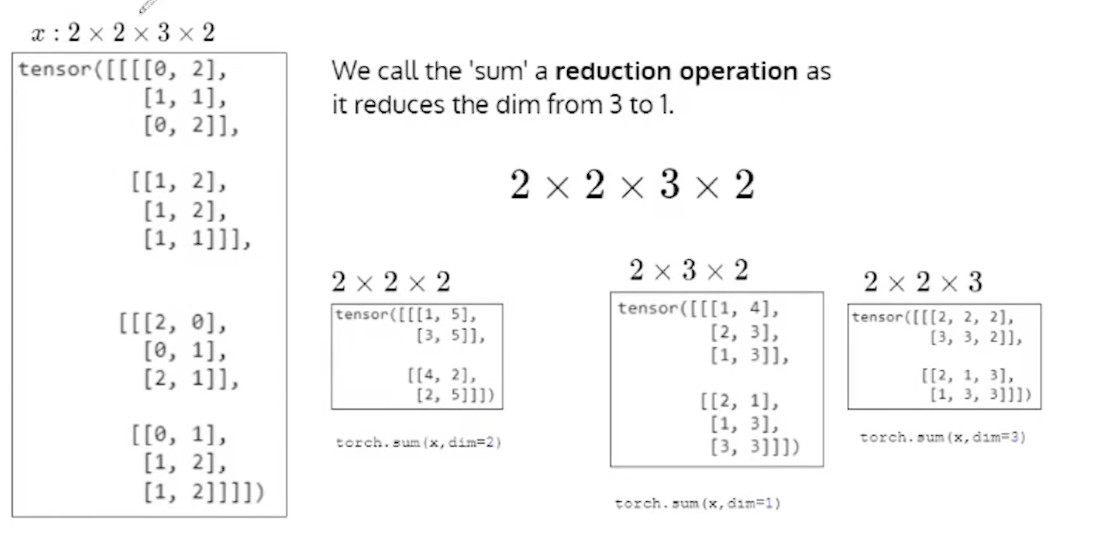

## AutoGrad: Calculating gradient

**Note:** AutoGrad is not `FiniteDiff`

baisically what this means is that it doesn't follow the typical way of finding the diffrentiation like we do:

So `FiniteDiff` Replaces hard calculus limits with simple slope formulas like $(\frac{f(x+h)-f(x)}{h})$ that means that instead of finding the exact derivative we try to approx it which unfortunately doesn't work in DL and thus we don't use it in `AutoGrad ` instead we use `AutoDiff`

> **Exact Reason:** The core difference is that backpropagation calculates mathematically exact derivatives in a single backward pass, while finite differences only approximate derivatives by repeatedly tweaking weights and re-running the network.


| Feature | Standard Backpropagation (Auto-Diff) | Finite Differences (Numerical) |
| :--- | :--- | :--- |
| **Method** | Uses the calculus chain rule to compute analytical derivatives. | Uses the slope formula $(\frac{f(w+h)-f(w)}{h})$ with a tiny step h. |
| **Accuracy** | Exact (up to standard floating-point precision). | Approximation (suffers from truncation and round-off errors). |
| **Speed / Cost** | Highly Efficient. Requires exactly 1 forward pass and 1 backward pass per batch. | Extremely Slow. Requires at least 1 extra forward pass per individual weight. |
| **Primary Use Case** | Training networks of any size (from small MLPs to massive LLMs). | Gradient checking (debugging custom backprop code on tiny models). |


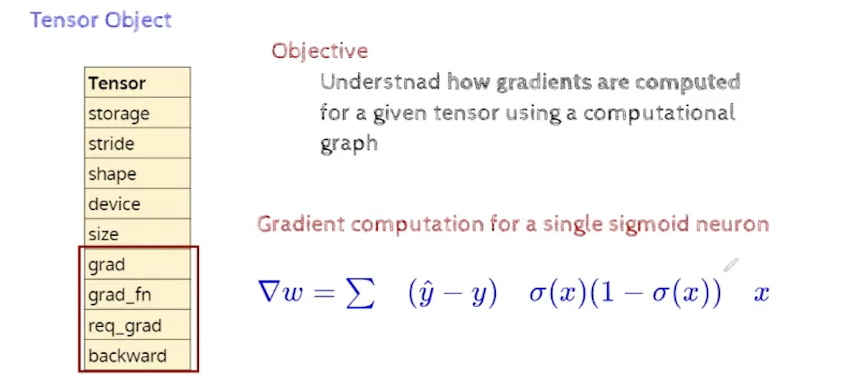

---

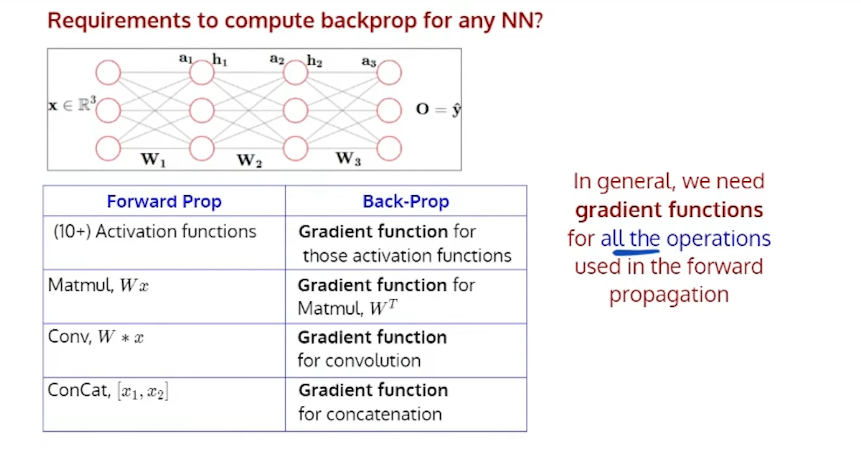

## These are some samples of implementations:


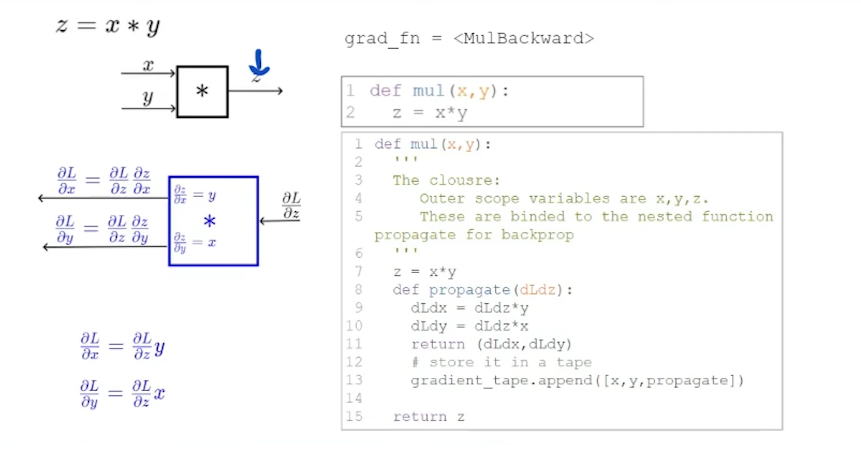

---

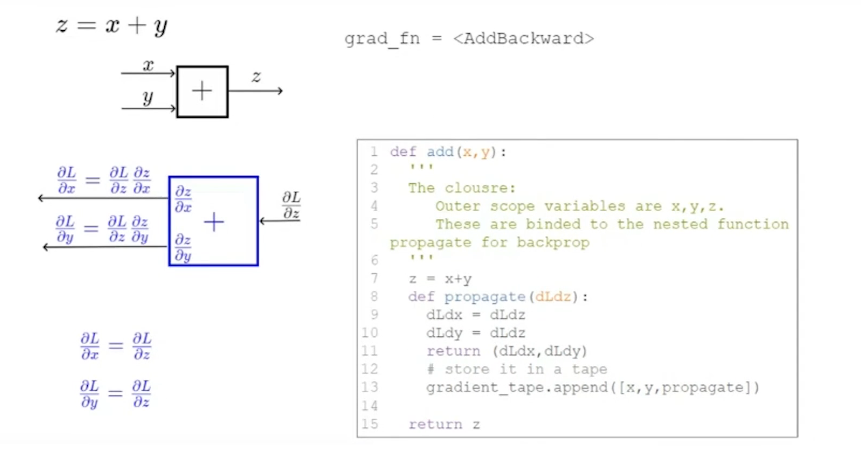

---

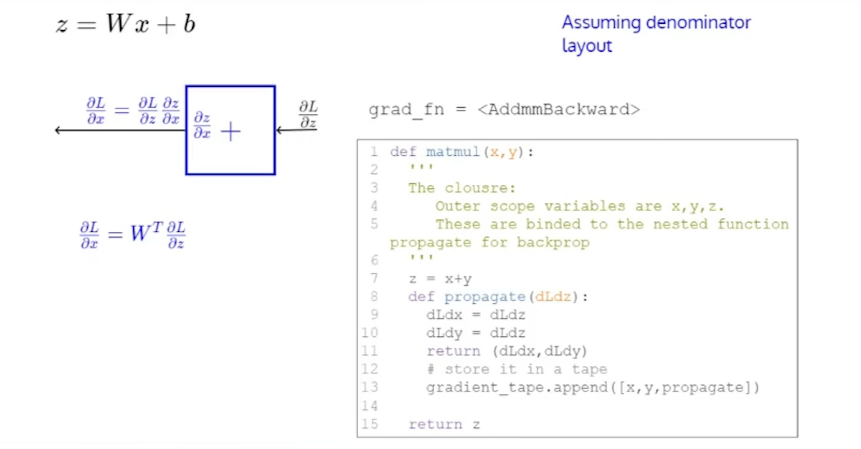

### *Try to get the essence and idea of this* - rest mostly everything is already defined

we can create 100's of operations like +,-,*,/,tanh,sigmoid...etc but we'll add both method in them Forward and the backward together..

In [ ]:
# forward pass
def sigmoid(z):
  # including the backward method
  def propagate():
    pass

#you can build anything with the base idea: like
# -->|*|-->o/p
def mul(x,y):
  z=x*y
  def propagate(dldz):
    dldx=dldz*y
    dldy=dldz*x
    return dldx,dldy

  return z,propagate

#you you can see we found both the fwd and bkwd together.. ref Notes or above to better understand..


In [ ]:
# if i want to code for say: tanh

def tanh(x):
  z= sigmoid(x)
  def propagate(dLdz):
    dLdz=dLdz*dtanh(x)
    return dLdz
    # store it in tape
    gradient_tape.append([x,propagate])
  return z

## Moving on: `Computational Graphs`

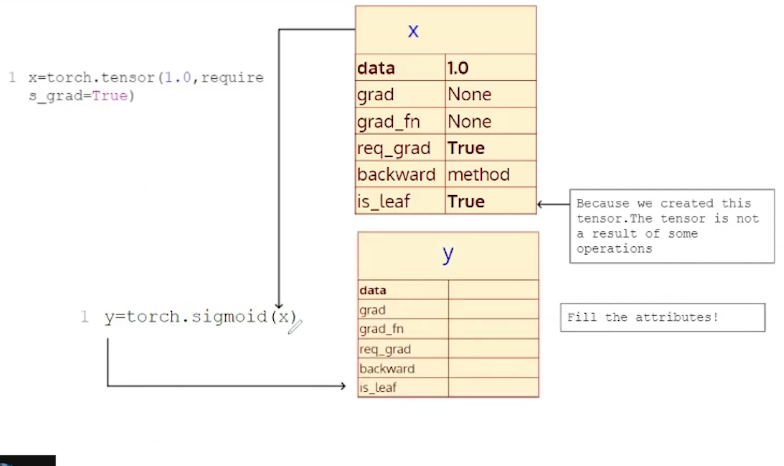

---

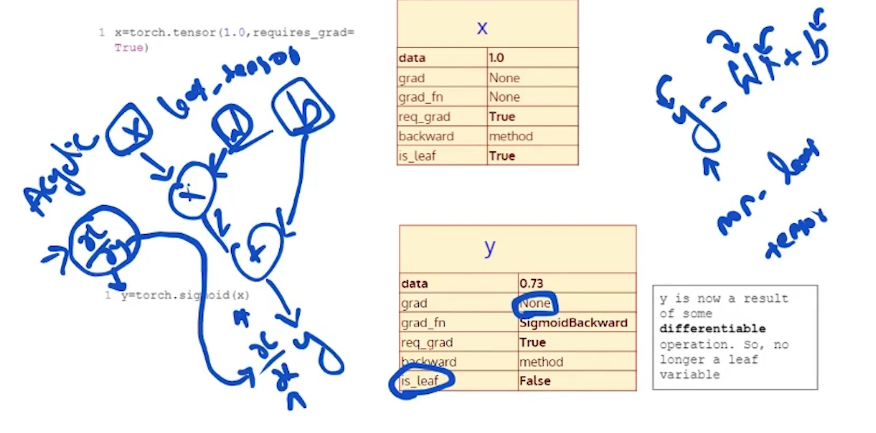

---



In [ ]:
import torch
from torch import tensor

In [ ]:
dir(torch.autograd)
dir(torch.autograd.Function) #we're looking for

['__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_backward_cls',
 '_compiled_autograd_backward_state',
 '_compiled_autograd_key',
 '_get_compiled_autograd_symints',
 '_input_metadata',
 '_is_pure_view',
 '_materialize_non_diff_grads',
 '_raw_saved_tensors',
 '_register_hook',
 '_register_hook_dict',
 '_sequence_nr',
 '_set_sequence_nr',
 'apply',
 'backward',
 'clear_saved_tensors_on_access',
 'dirty_tensors',
 'forward',
 'generate_vmap_rule',
 'jvp',
 'mark_dirty',
 'mark_non_differentiable',
 'mark_shared_storage',
 'materialize_grads',
 'maybe_clear_saved_tensors',
 'metadata',
 'name',
 'n

In [ ]:
x=tensor([1.0]) #leaf variables
y=torch.sigmoid(x)
x

tensor([1.])

In [ ]:
display(x.data,
x.grad, x.requires_grad, x.backward, x.is_leaf)

tensor([1.])

None

False

<bound method Tensor.backward of tensor([1.])>

True

In [ ]:
y.is_leaf

True

## Imp


In [ ]:
x=tensor(1.0, requires_grad=True, dtype=torch.float64) #note torch has it's own flat dtype
y=2*torch.sigmoid(x)
print(y)
#note we got: <MulBackward0> what we discussed

tensor(1.4621, dtype=torch.float64, grad_fn=<MulBackward0>)


In [ ]:
print(x.is_leaf, y.is_leaf)
print(x.grad_fn, y.grad_fn)

True False
None <MulBackward0 object at 0x792f4eab81f0>


The moment you run `y.backward()` we'll get the accumulated gradient..  [ref: Computation Graph Notes]

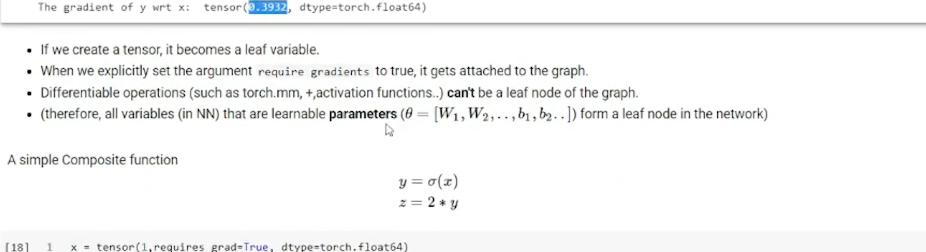

In [ ]:
y.backward()

In [ ]:
print("The gradient of y wrt x : ", x.grad) #0.39 as we've got in computation graph notes..

The gradient of y wrt x :  tensor(0.3932, dtype=torch.float64)


## if you want tot get the gradient of non-leaf tensor `retain_grad`

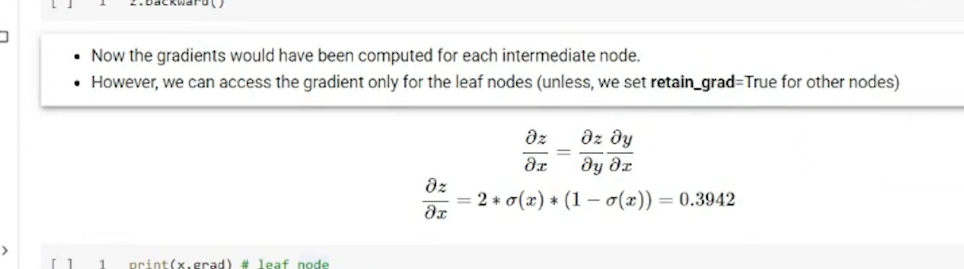

## Static Graph -> `storing the grads instead of deleted them in runtime`

In [ ]:
x=tensor(1,requires_grad=True, dtype=torch.float)
y=torch.sigmoid(x)


In [ ]:
y.backward(retain_graph=True)
print(x.grad)

tensor(0.3932)


In [ ]:
y.backward(retain_graph=True)
print(x.grad)
#as you can see it incerase means the prev value was retained - accumulating

tensor(0.5898)


In [ ]:
y.backward() # this deletes the grads..

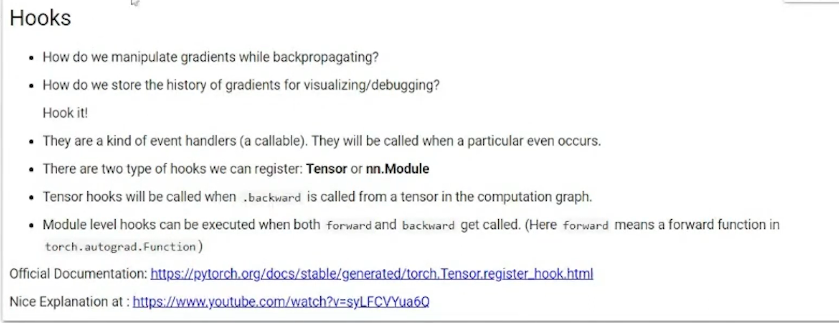

## Hooks
How do we manipulate gradients while backpropagating?
- How do we store the history of gradients for visualizing/debugging?

Hook it!

- They are a kind of event handlers (a callable).
- They will be called when a particular even occurs.
- There are two type of hooks we can register: Tensor or nn.Module
- Tensor hooks will be called when backward is called from a tensor in the computation graph.
- Module level hooks can be executed when both forward and backward get called.
- (Here forward means a forward function in torch.autograd.Function)

> Official Documentation: https://pytorch.org/docs/stable/generated/torch.Tensor.register_hook.html \
> Nice Explanation at: https://www.youtube.com/watch?v=syLFCVYuaбо

In [ ]:
#example
x=tensor(1,requires_grad=True, dtype=torch.float)
y=torch.sigmoid(x)
z= 2*y

- signature: `hook(grad) -> tensor or None`
- it's a callable object and takes in `Tensor.grad` as input(`.grad` is automatically passed to the hooks)

In [ ]:
def y_hook(grad):
  print(f'Grad y wrt z in now:', grad)

In [ ]:
y.register_hook(y_hook)

In [ ]:
z.backward()

Grad y wrt z in now: tensor(2.)


In [ ]:
y.grad

/tmp/ipykernel_722/486760323.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  y.grad
